In [13]:
import os
import numpy as np  # Xử lý tính toán số học
import pandas as pd  # Thao tác và xử lý bảng dữ liệu
import matplotlib.pyplot as plt  # Vẽ biểu đồ
import matplotlib as mpl
from sklearn import tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV, train_test_split

In [14]:
df_diabetes = pd.read_csv('data/diabetes_prediction_dataset.csv')

In [15]:
df_diabetes.head()

,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
0,Female,80.0,0,1,never,25.19,6.6,140,0
1,Female,54.0,0,0,No Info,27.32,6.6,80,0
2,Male,28.0,0,0,never,27.32,5.7,158,0
3,Female,36.0,0,0,current,23.45,5.0,155,0
4,Male,76.0,1,1,current,20.14,4.8,155,0


In [16]:
df_diabetes.info()

<class 'pandas.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 9 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   gender               100000 non-null  str    
 1   age                  100000 non-null  float64
 2   hypertension         100000 non-null  int64  
 3   heart_disease        100000 non-null  int64  
 4   smoking_history      100000 non-null  str    
 5   bmi                  100000 non-null  float64
 6   HbA1c_level          100000 non-null  float64
 7   blood_glucose_level  100000 non-null  int64  
 8   diabetes             100000 non-null  int64  
dtypes: float64(3), int64(4), str(2)
memory usage: 6.9 MB


In [17]:
df_diabetes['gender'] = df_diabetes['gender'].replace(['Male', 'Female', 'Other'], [0, 1, 2])

# Mã hóa cột smoking_history thành dạng số
smoking_map = {'never': 0, 'No Info': 1, 'current': 2, 'former': 3, 'ever': 4, 'not current': 5}
df_diabetes['smoking_history'] = df_diabetes['smoking_history'].map(smoking_map).fillna(1).astype(int)

# Xử lý giá trị khuyết (nếu có)
df_diabetes['age'] = df_diabetes['age'].fillna(df_diabetes['age'].median()).astype(float)
df_diabetes['bmi'] = df_diabetes['bmi'].fillna(df_diabetes['bmi'].median()).astype(float)
df_diabetes['HbA1c_level'] = df_diabetes['HbA1c_level'].fillna(df_diabetes['HbA1c_level'].median()).astype(float)
df_diabetes['blood_glucose_level'] = df_diabetes['blood_glucose_level'].fillna(df_diabetes['blood_glucose_level'].median()).astype(float)

# 1.2 Phân tách Features (X) và Target (y)
feature_cols = [
    'gender', 'age', 'hypertension', 'heart_disease', 
    'smoking_history', 'bmi', 'HbA1c_level', 'blood_glucose_level'
]

X = df_diabetes[feature_cols].values
y = df_diabetes['diabetes'].values

In [18]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, 
    test_size=0.2, 
    random_state=42, 
    stratify=y  # Giữ nguyên tỷ lệ phân bố nhãn 0 và 1 ở cả 2 tập
)

print(f"Kích thước tập X_train: {X_train.shape}, y_train: {y_train.shape}")
print(f"Kích thước tập X_test:  {X_test.shape}, y_test: {y_test.shape}")

Kích thước tập X_train: (80000, 8), y_train: (80000,)
Kích thước tập X_test:  (20000, 8), y_test: (20000,)


In [19]:

params = {'max_depth': [1, 2, 4, 6, 8, 10, 12]}
dt = tree.DecisionTreeClassifier(random_state=42)

cv_dt = GridSearchCV(
    dt, param_grid=params, scoring='roc_auc',
    n_jobs=-1, refit=True, cv=4, verbose=1,
    return_train_score=True
)

# CHỈ huấn luyện (fit) trên tập X_train, y_train
cv_dt.fit(X_train, y_train)

Fitting 4 folds for each of 7 candidates, totalling 28 fits


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",DecisionTreeC...ndom_state=42)
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'max_depth': [1, 2, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'roc_auc'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",4
,"verbose verbose: int, default=0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",1
,"return_train_score return_train_score: bool, default=FalseIf ``False``, the ``cv_results_`` attribute will not include trainingscores.Computing training scores is used to get insights on how differentparameter settings impact the overfitting/underfitting trade-off.However computing the scores on the training set can be computationallyexpensive and is not strictly required to select the parameters thatyield the best generalization performance... versionadded:: 0.19.. versionchanged:: 0.21 Default value was changed from ``True`` to ``False``",True
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be availa

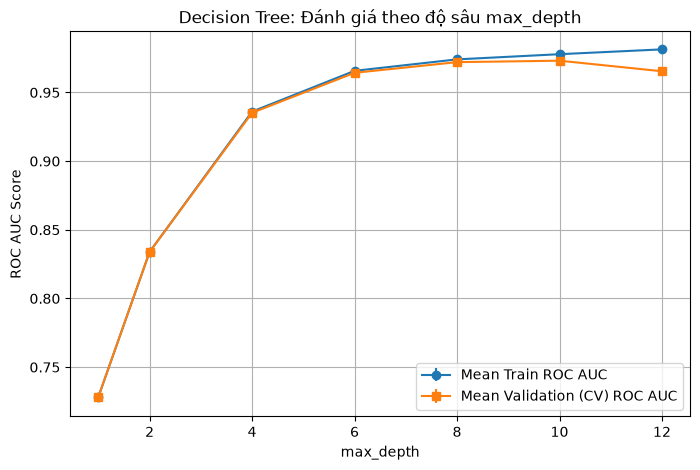

In [20]:
cv_dt_results = pd.DataFrame(cv_dt.cv_results_)

plt.figure(figsize=(8, 5))
plt.errorbar(
    cv_dt_results['param_max_depth'], cv_dt_results['mean_train_score'],
    yerr=cv_dt_results['std_train_score'] / np.sqrt(4),
    label='Mean Train ROC AUC', marker='o'
)
plt.errorbar(
    cv_dt_results['param_max_depth'], cv_dt_results['mean_test_score'],
    yerr=cv_dt_results['std_test_score'] / np.sqrt(4),
    label='Mean Validation (CV) ROC AUC', marker='s'
)
plt.xlabel('max_depth')
plt.ylabel('ROC AUC Score')
plt.title('Decision Tree: Đánh giá theo độ sâu max_depth')
plt.legend()
plt.grid(True)
plt.show()

In [21]:
rf = RandomForestClassifier(
    criterion='gini', max_depth=3, max_features='sqrt',
    bootstrap=True, n_jobs=-1, random_state=42
)

rf_params = {'n_estimators': list(range(10, 110, 10))}

cv_rf = GridSearchCV(
    rf, param_grid=rf_params, scoring='roc_auc',
    n_jobs=-1, refit=True, cv=4, verbose=1,
    return_train_score=True
)

# CHỈ huấn luyện (fit) trên tập X_train, y_train
cv_rf.fit(X_train, y_train)

Fitting 4 folds for each of 10 candidates, totalling 40 fits


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",RandomForestC...ndom_state=42)
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'n_estimators': [10, 20, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'roc_auc'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",4
,"verbose verbose: int, default=0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",1
,"return_train_score return_train_score: bool, default=FalseIf ``False``, the ``cv_results_`` attribute will not include trainingscores.Computing training scores is used to get insights on how differentparameter settings impact the overfitting/underfitting trade-off.However computing the scores on the training set can be computationallyexpensive and is not strictly required to select the parameters thatyield the best generalization performance... versionadded:: 0.19.. versionchanged:: 0.21 Default value was changed from ``True`` to ``False``",True
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be a

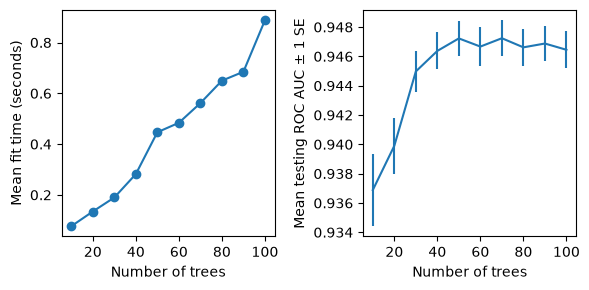

In [22]:
cv_rf_ex_results_df = pd.DataFrame(cv_rf.cv_results_)

fig, axs = plt.subplots(nrows=1, ncols=2, figsize=(6, 3))

# Biểu đồ 1: Thời gian huấn luyện (mean_fit_time) theo số lượng cây
axs[0].plot(
    cv_rf_ex_results_df['param_n_estimators'],
    cv_rf_ex_results_df['mean_fit_time'],
    '-o'
)
axs[0].set_xlabel('Number of trees')
axs[0].set_ylabel('Mean fit time (seconds)')

# Biểu đồ 2: ROC AUC Testing score kèm sai số chuẩn (+- 1 SE)
axs[1].errorbar(
    cv_rf_ex_results_df['param_n_estimators'],
    cv_rf_ex_results_df['mean_test_score'],
    yerr=cv_rf_ex_results_df['std_test_score'] / np.sqrt(4)
)
axs[1].set_xlabel('Number of trees')
axs[1].set_ylabel(r'Mean testing ROC AUC $\pm$ 1 SE')

plt.tight_layout()
plt.show()

In [23]:
# ==============================================================================
# Thực hiện import thư viện và xây dựng mô hình SVM cho bài toán dự đoán tiểu đường
# ==============================================================================
from sklearn.svm import SVC
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix

# 1. Khởi tạo mô hình SVC
# Lưu ý: Tập dữ liệu của bạn có 80.000 mẫu huấn luyện. Mô hình SVM với kernel RBF (mặc định)
# có độ phức tạp O(n^2 đến n^3), nếu dùng C=100 và gamma=0.001 trên toàn bộ 80.000 mẫu
# thời gian chạy có thể rất lâu. Do đó, khuyến nghị dùng C=1.0 hoặc dùng tập con nếu muốn thử nghiệm nhanh.
svc = SVC(gamma=0.001, C=100, random_state=42)

# 2. Huấn luyện mô hình trên tập X_train và y_train đã chia từ trước (80.000 mẫu)
# Nếu muốn chạy thử nghiệm nhanh trong vài giây, bạn có thể huấn luyện trên 5.000 - 10.000 mẫu:
# svc.fit(X_train[:10000], y_train[:10000])
svc.fit(X_train, y_train)

# 3. Dự đoán nhãn trên tập kiểm thử X_test (20.000 mẫu)
y_pred = svc.predict(X_test)

# 4. Đánh giá kết quả mô hình
print("Độ chính xác (Accuracy):", accuracy_score(y_test, y_pred))
print("\nBáo cáo chi tiết (Classification Report):")
print(classification_report(y_test, y_pred))

# 5. So sánh trực quan một số kết quả dự đoán với thực tế
comparison = list(zip(y_pred[:10], y_test[:10]))
print("\nSo sánh 10 mẫu đầu tiên (Dự đoán, Thực tế):", comparison)

Độ chính xác (Accuracy): 0.9635

Báo cáo chi tiết (Classification Report):
              precision    recall  f1-score   support

           0       0.96      1.00      0.98     18300
           1       0.97      0.59      0.73      1700

    accuracy                           0.96     20000
   macro avg       0.97      0.79      0.86     20000
weighted avg       0.96      0.96      0.96     20000


So sánh 10 mẫu đầu tiên (Dự đoán, Thực tế): [(np.int64(0), np.int64(0)), (np.int64(0), np.int64(0)), (np.int64(0), np.int64(0)), (np.int64(0), np.int64(0)), (np.int64(0), np.int64(0)), (np.int64(0), np.int64(0)), (np.int64(0), np.int64(0)), (np.int64(1), np.int64(1)), (np.int64(0), np.int64(0)), (np.int64(1), np.int64(0))]


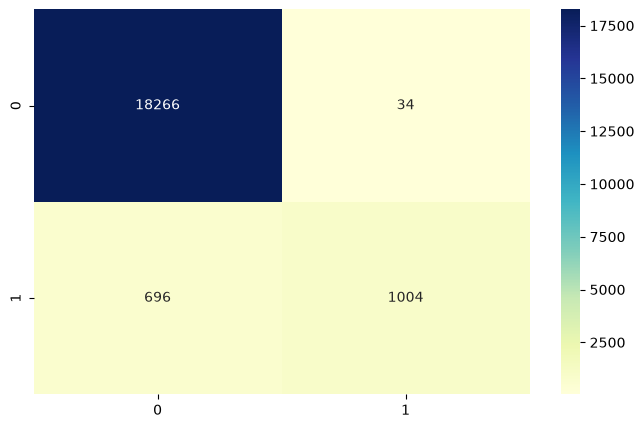

In [24]:
import seaborn as sns
cm = confusion_matrix(y_test, y_pred)
conf_matrix = pd.DataFrame(data = cm)
plt.figure(figsize = (8,5))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap="YlGnBu");
plt.show()